# Análise de correlação entre avaliações e variáveis comerciais — Amazon

### 1. Preparação e tratamento dos dados

O estudo investiga associações lineares entre `rating` e preço original, preço com desconto, percentual de desconto e quantidade de avaliações. A unidade de análise é o **produto único**: após a importação, é mantido apenas um registro por `product_id`, priorizando o maior `rating_count` numérico. Em caso de empate, mantém-se a primeira ocorrência original.

Em seguida, as categorias são separadas em três níveis e os campos quantitativos são convertidos para formatos numéricos. Valores inválidos são tratados como ausentes (`NaN`).

In [1]:
# Bibliotecas para tratamento, análise estatística e visualização
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from scipy import stats

In [2]:
# Subindo a base de dados:
df = pd.read_csv('amazon.csv')

In [3]:
# Deduplicação por produto: selecionar o registro com maior quantidade de avaliações
# rating_count é texto no CSV (ex.: "43,994"); converter ANTES de ordenar.
tamanho_antes = len(df)
df['_rating_count_ord'] = pd.to_numeric(
    df['rating_count'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)
# Ordenação estável: em caso de empate, mantém a primeira linha do CSV.
df = (df.sort_values('_rating_count_ord', ascending=False, kind='stable')
        .drop_duplicates(subset='product_id', keep='first')
        .drop(columns='_rating_count_ord')
        .sort_index())
tamanho_depois = len(df)
print(f"Linhas antes: {tamanho_antes} | Linhas depois: {tamanho_depois} | Registros removidos: {tamanho_antes - tamanho_depois}")

Linhas antes: 1465 | Linhas depois: 1351 | Registros removidos: 114


In [4]:
# 1. Garantir que a coluna seja criada
df['first_category_level'] = df['category'].str.split('|').str[0]

# 2. Usamos str.split('|').str[1] para capturar a string entre a primeira e a segunda barra
df['second_category_level'] = df['category'].str.split('|').str[1]

# 3. Usamos str.split('|').str[2] para capturar a string entre a primeira e a segunda barra
df['third_category_level'] = df['category'].str.split('|').str[2]

# 3. Configurar o pandas para exibir todas as colunas sem truncar no head()
pd.set_option('display.max_columns', None)

# 4. Exibir as primeiras linhas para confirmar que todas as colunas (incluindo a nova no final) aparecem
display(df.head())

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,first_category_level,second_category_level,third_category_level
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,Computers&Accessories,Accessories&Peripherals,Cables&Accessories
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...,Computers&Accessories,Accessories&Peripherals,Cables&Accessories
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,Computers&Accessories,Accessories&Peripherals,Cables&Accessories
5,B08Y1TFSP6,pTron Solero TB301 3A Type-C Data and Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹149,"₹1,000",85%,3.9,"24,871",Fast Charging & Data Sync: Solero TB301 Type-C...,"AEQ2YMXSZWEOHK2EHTNLOS56YTZQ,AGRVINWECNY7323CW...","Jayesh,Rajesh k.,Soopy,amazon customer,Aman,Sh...","R7S8ANNSDPR40,R3CLZFLHVJU26P,RFF7U7MPQFUGR,R1M...","It's pretty good,Average quality,very good and...","It's a good product.,Like,Very good item stron...",https://m.media-amazon.com/images/I/31wOPjcSxl...,https://www.amazon.in/Solero-TB301-Charging-48...,Computers&Accessories,Accessories&Peripherals,Cables&Accessories
7,B08DDRGWTJ,MI Usb Type-C Cable Smartphone (Black),Computers&Accessories|Accessories&Peripherals|...,₹229,₹299,23%,4.3,"30,411",1m long Type-C USB Cable|Sturdy and Durable. W...,"AHW6E5LQ2BDYOIVLAJGDH45J5V5Q,AF74RSGCHPZITVFSZ...","Pavan A H,Jayesh bagad,Shridhar,rajendran,karu...","R2X090D1YHACKR,R32ZCIH9AFNJ60,R3N57EVVG0EHAF,R...","Worth for money - suitable for Android auto,Go...",Worth for money - suitable for Android auto......,https://m.media-amazon.com/images/I/31XO-wfGGG...,https://www.amazon.in/MI-MTCY001IN-USB-Type-C-...,Computers&Accessories,Accessories&Peripherals,Cables&Accessories


In [5]:
# Criando uma cópia para evitar warnings do pandas
df_qt_num = df.copy()

# 1. Limpeza de 'discounted_price' e 'actual_price': remove '₹' e ','
for col in ['discounted_price', 'actual_price']:
    df_qt_num[col] = df_qt_num[col].astype(str).str.replace('₹', '').str.replace(',', '')
    df_qt_num[col] = pd.to_numeric(df_qt_num[col], errors='coerce')

# 2. Limpeza de 'discount_percentage': remove '%'
df_qt_num['discount_percentage'] = df_qt_num['discount_percentage'].astype(str).str.replace('%', '')
df_qt_num['discount_percentage'] = pd.to_numeric(df_qt_num['discount_percentage'], errors='coerce')

# 3. Limpeza de 'rating': trata caracteres inválidos como '|'
df_qt_num['rating'] = pd.to_numeric(df_qt_num['rating'], errors='coerce')

# 4. Limpeza de 'rating_count': remove as vírgulas ','
df_qt_num['rating_count'] = df_qt_num['rating_count'].astype(str).str.replace(',', '')
df_qt_num['rating_count'] = pd.to_numeric(df_qt_num['rating_count'], errors='coerce')

# Substitui o dataframe pd_qt original pelo dataframe limpo
df = df_qt_num

# Visualizando os tipos de dados após a conversão
df.dtypes

product_id                object
product_name              object
category                  object
discounted_price         float64
actual_price             float64
discount_percentage        int64
rating                   float64
rating_count             float64
about_product             object
user_id                   object
user_name                 object
review_id                 object
review_title              object
review_content            object
img_link                  object
product_link              object
first_category_level      object
second_category_level     object
third_category_level      object
dtype: object

In [6]:
df_qt = df[["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]]

In [7]:
# visualizando alguns dados
df_qt.head()

,discounted_price,actual_price,discount_percentage,rating,rating_count
1,199.0,349.0,43,4.0,43994.0
2,199.0,1899.0,90,3.9,7928.0
4,154.0,399.0,61,4.2,16905.0
5,149.0,1000.0,85,3.9,24871.0
7,229.0,299.0,23,4.3,30411.0


In [8]:
df_qt.dtypes

discounted_price       float64
actual_price           float64
discount_percentage      int64
rating                 float64
rating_count           float64
dtype: object

In [9]:
# Exibe as primeiras linhas para confirmar a conversão
display(df_qt.head())

,discounted_price,actual_price,discount_percentage,rating,rating_count
1,199.0,349.0,43,4.0,43994.0
2,199.0,1899.0,90,3.9,7928.0
4,154.0,399.0,61,4.2,16905.0
5,149.0,1000.0,85,3.9,24871.0
7,229.0,299.0,23,4.3,30411.0


### 2. Análise exploratória das variáveis

A base é avaliada após a deduplicação para verificar dimensões, valores ausentes, estatísticas descritivas e possíveis valores extremos. Histogramas e boxplots ajudam a caracterizar a distribuição das avaliações e das variáveis comerciais.

**Nota:** os preços são expressos em rúpias indianas (₹). Valores extremos não são excluídos automaticamente; podem influenciar a correlação de Pearson e devem ser considerados na interpretação.

In [10]:
# Analisando linhas e colunas
df_qt.shape

(1351, 5)

In [11]:
# Analisando valores nulas na base
df_qt.isnull().sum()

discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           2
dtype: int64

In [12]:
# descritivo das variáveis: medidas resumo
df_qt.describe().round(2)

,discounted_price,actual_price,discount_percentage,rating,rating_count
count,1351.00,1351.00,1351.00,1350.00,1349.00
mean,3304.65,5691.18,46.69,4.09,17644.52
std,7174.00,11218.67,21.63,0.30,42145.66
min,39.00,39.00,0.00,2.00,2.00
25%,349.00,899.00,31.00,3.90,1106.00
50%,899.00,1795.00,49.00,4.10,4740.00
75%,2174.00,4575.00,62.00,4.30,16020.00
max,77990.00,139900.00,94.00,5.00,426973.00


Text(0.5, 1.0, 'Histograma rating')

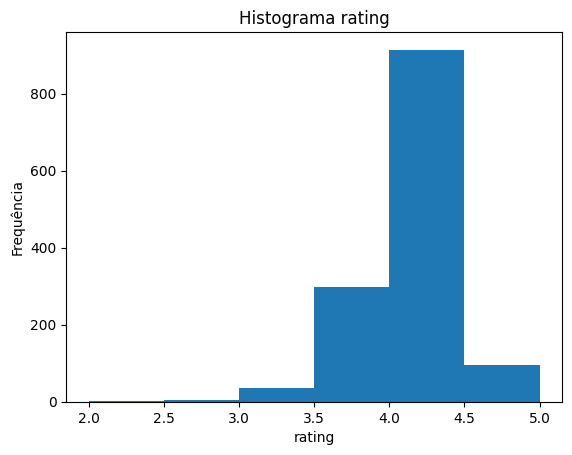

In [13]:
# Histograma da variável target

plt.hist(df_qt['rating'], bins=6)

plt.ylabel('Frequência')
plt.xlabel('rating')
plt.title('Histograma rating')

Text(0, 0.5, 'Soma da qtde de avaliações')

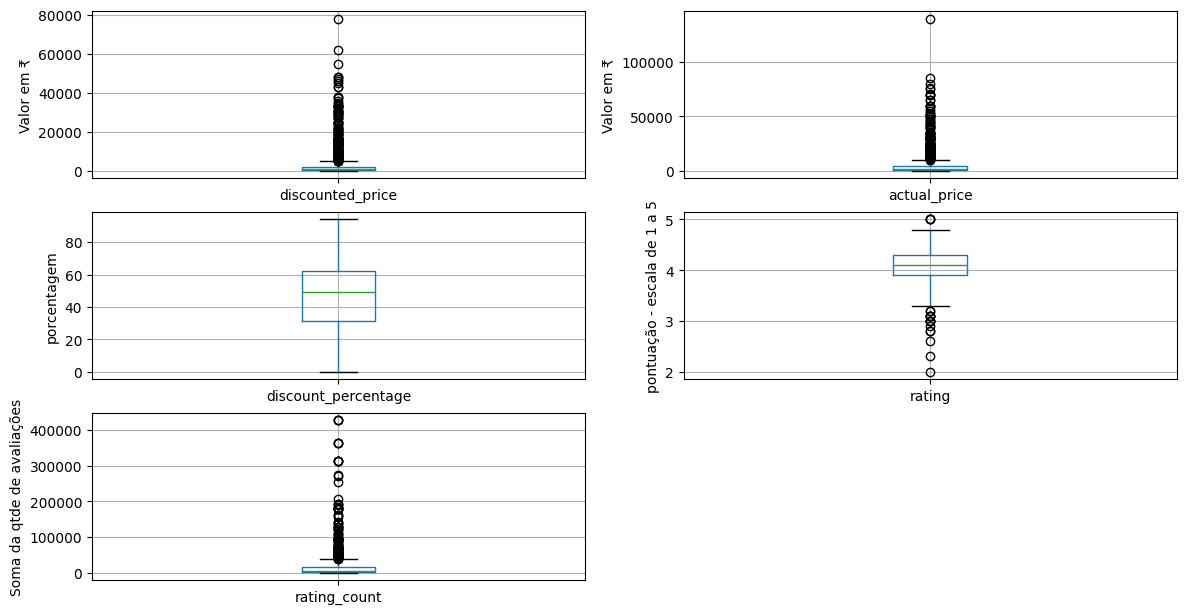

In [14]:
# Avaliando as variáveis quantitativas Boxplot: para visualizar Outliers

plt.figure(figsize=(14,10))


plt.subplot(4, 2, 1)
fig = df_qt.boxplot(column='discounted_price')
fig.set_title('')
fig.set_ylabel('Valor em ₹')


plt.subplot(4, 2, 2)
fig = df_qt.boxplot(column='actual_price')
fig.set_title('')
fig.set_ylabel('Valor em ₹')


plt.subplot(4, 2, 3)
fig = df_qt.boxplot(column='discount_percentage')
fig.set_title('')
fig.set_ylabel('porcentagem')


plt.subplot(4, 2, 4)
fig = df_qt.boxplot(column='rating')
fig.set_title('')
fig.set_ylabel('pontuação - escala de 1 a 5')


plt.subplot(4, 2, 5)
fig = df_qt.boxplot(column='rating_count')
fig.set_title('')
fig.set_ylabel('Soma da qtde de avaliações')

### 3. Correlação de Pearson — base de produtos únicos

A matriz de correlação apresenta as associações lineares na base deduplicada e serve de referência para os resultados segmentados. Coeficientes próximos de zero indicam pouca associação **linear**, mas não descartam relações não lineares.

O coeficiente de Pearson não indica causalidade nem, isoladamente, significância estatística.

<Axes: >

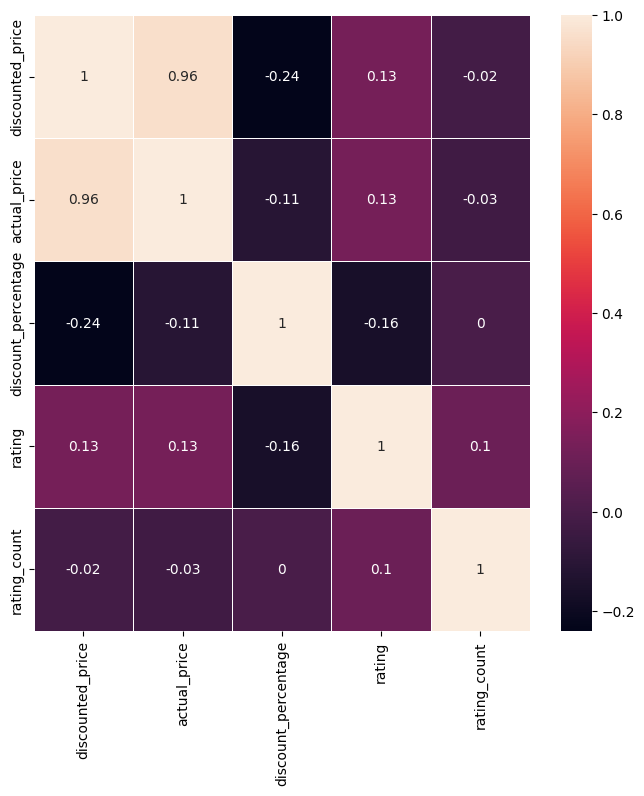

In [15]:
correlation_matrix = df_qt.corr().round(2)

fig, ax = plt.subplots(figsize=(8,8))
sb.heatmap(data=correlation_matrix, annot=True, linewidths=.5, ax=ax)

### 4. Análise segmentada por categorias

Os produtos são agrupados nos três primeiros níveis da variável `category`, permitindo comparar a correlação geral com segmentos potencialmente mais homogêneos. Os heatmaps são apresentados apenas para grupos com **pelo menos 50 produtos**; esse filtro é exploratório, não um teste de significância.

**Limitação:** os níveis 2 e 3 são agrupados pelo nome da categoria isoladamente, sem preservar o caminho hierárquico completo. Categorias homônimas de ramos diferentes podem ser reunidas.

In [16]:
# Visualizando os valores únicos da coluna de categorias criada anteriormente
valores_unicos = df['first_category_level'].unique()
print("Valores únicos da coluna:")
print(valores_unicos)

print("\nQuantidade de valores únicos:")
print(df['first_category_level'].nunique())

Valores únicos da coluna:
['Computers&Accessories' 'Electronics' 'MusicalInstruments'
 'OfficeProducts' 'Home&Kitchen' 'HomeImprovement' 'Toys&Games'
 'Car&Motorbike' 'Health&PersonalCare']

Quantidade de valores únicos:
9


In [17]:
# Exemplo de como visualizar o DataFrame de uma categoria específica (ex: Computers_Accessories)
#display(dfs_categorias['Computers_Accessories'].head())

In [18]:
# Criando um dicionário para armazenar o DataFrame de cada categoria
dfs_categorias = {}

# Filtrando e criando um DataFrame para cada categoria única
for categoria in df['first_category_level'].unique():
    # Substitui caracteres especiais como '&' para criar nomes de chaves mais limpos
    chave_categoria = categoria.replace('&', '_')
    dfs_categorias[chave_categoria] = df[df['first_category_level'] == categoria].copy()
    print(f"DataFrame criado para: '{chave_categoria}' com {len(dfs_categorias[chave_categoria])} registros.")

DataFrame criado para: 'Computers_Accessories' com 375 registros.
DataFrame criado para: 'Electronics' com 490 registros.
DataFrame criado para: 'MusicalInstruments' com 2 registros.
DataFrame criado para: 'OfficeProducts' com 31 registros.
DataFrame criado para: 'Home_Kitchen' com 448 registros.
DataFrame criado para: 'HomeImprovement' com 2 registros.
DataFrame criado para: 'Toys_Games' com 1 registros.
DataFrame criado para: 'Car_Motorbike' com 1 registros.
DataFrame criado para: 'Health_PersonalCare' com 1 registros.


In [19]:
# Colunas desejadas
colunas_filtradas = ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']

# Filtrando as colunas em cada DataFrame do dicionário
for chave in dfs_categorias.keys():
    dfs_categorias[chave] = dfs_categorias[chave][colunas_filtradas]

# Exibindo o cabeçalho de um dos DataFrames para confirmar a alteração
print("Colunas no DataFrame de 'Computers_Accessories' após a filtragem:")
display(dfs_categorias['Computers_Accessories'].head())

Colunas no DataFrame de 'Computers_Accessories' após a filtragem:


,discounted_price,actual_price,discount_percentage,rating,rating_count
1,199.0,349.0,43,4.0,43994.0
2,199.0,1899.0,90,3.9,7928.0
4,154.0,399.0,61,4.2,16905.0
5,149.0,1000.0,85,3.9,24871.0
7,229.0,299.0,23,4.3,30411.0


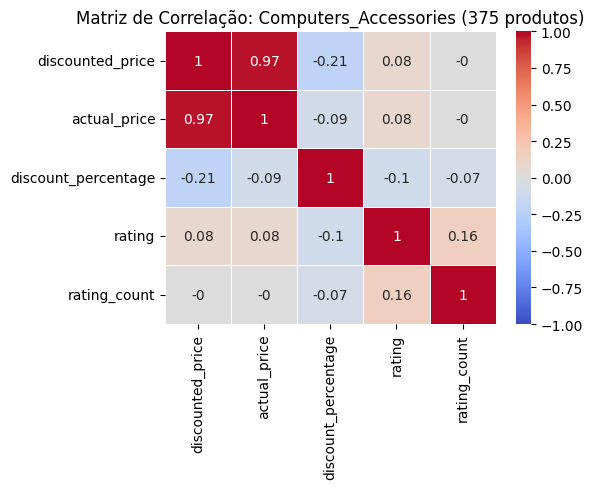

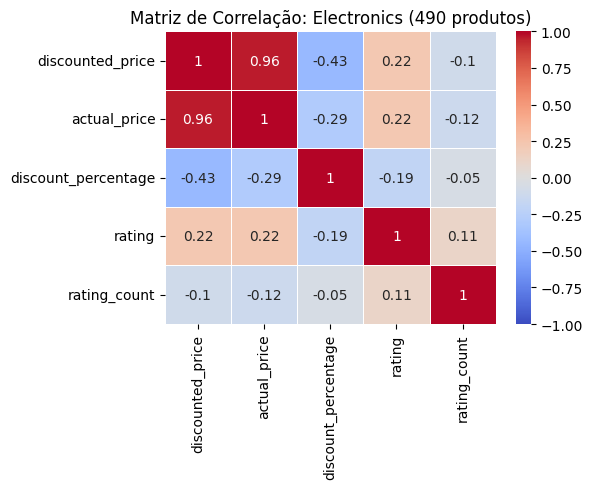

Categoria 'MusicalInstruments' possui apenas 2 registro(s). Correlação não calculada.
Categoria 'OfficeProducts' possui apenas 31 registro(s). Correlação não calculada.


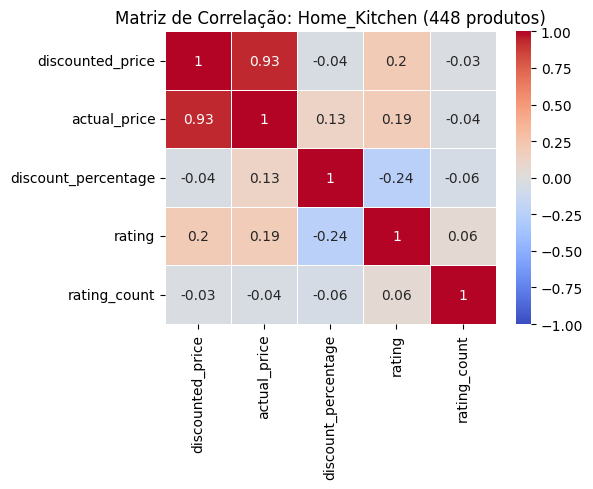

Categoria 'HomeImprovement' possui apenas 2 registro(s). Correlação não calculada.
Categoria 'Toys_Games' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'Car_Motorbike' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'Health_PersonalCare' possui apenas 1 registro(s). Correlação não calculada.


In [20]:
# Gerando o gráfico de correlação para cada categoria de produto
for nome_categoria, df_cat in dfs_categorias.items():
    # Verificamos se há registros suficientes para apresentar a matriz exploratória com amostra mínima
    if len(df_cat) >= 50:
        correlation_matrix = df_cat.corr().round(2)

        fig, ax = plt.subplots(figsize=(6, 5))
        sb.heatmap(data=correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=.5, ax=ax)
        ax.set_title(f"Matriz de Correlação: {nome_categoria} ({len(df_cat)} produtos)")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Categoria '{nome_categoria}' possui apenas {len(df_cat)} registro(s). Correlação não calculada.")

In [21]:
# Visualizando os valores únicos da coluna de categorias criada anteriormente
valores_unicos = df['second_category_level'].unique()
print("Valores únicos da coluna:")
print(valores_unicos)

print("\nQuantidade de valores únicos:")
print(df['second_category_level'].nunique())

Valores únicos da coluna:
['Accessories&Peripherals' 'NetworkingDevices' 'HomeTheater,TV&Video'
 'HomeAudio' 'WearableTechnology' 'Mobiles&Accessories'
 'Headphones,Earbuds&Accessories' 'Accessories'
 'ExternalDevices&DataStorage' 'Microphones'
 'GeneralPurposeBatteries&BatteryChargers' 'OfficePaperProducts'
 'CraftMaterials' 'Cameras&Photography' 'OfficeElectronics'
 'Printers,Inks&Accessories' 'Monitors' 'Components' 'Electrical'
 'Arts&Crafts' 'PowerAccessories' 'Tablets' 'Laptops'
 'Kitchen&HomeAppliances' 'Heating,Cooling&AirQuality' 'Kitchen&Dining'
 'HomeStorage&Organization' 'CarAccessories'
 'HomeMedicalSupplies&Equipment']

Quantidade de valores únicos:
29


In [22]:
# Criando um dicionário para armazenar o DataFrame de cada categoria
dfs_categorias = {}

# Filtrando e criando um DataFrame para cada categoria única
for categoria in df['second_category_level'].unique():
    # Substitui caracteres especiais como '&' para criar nomes de chaves mais limpos
    chave_categoria = categoria.replace('&', '_')
    dfs_categorias[chave_categoria] = df[df['second_category_level'] == categoria].copy()
    print(f"DataFrame criado para: '{chave_categoria}' com {len(dfs_categorias[chave_categoria])} registros.")

DataFrame criado para: 'Accessories_Peripherals' com 307 registros.
DataFrame criado para: 'NetworkingDevices' com 30 registros.
DataFrame criado para: 'HomeTheater,TV_Video' com 156 registros.
DataFrame criado para: 'HomeAudio' com 16 registros.
DataFrame criado para: 'WearableTechnology' com 62 registros.
DataFrame criado para: 'Mobiles_Accessories' com 151 registros.
DataFrame criado para: 'Headphones,Earbuds_Accessories' com 63 registros.
DataFrame criado para: 'Accessories' com 11 registros.
DataFrame criado para: 'ExternalDevices_DataStorage' com 18 registros.
DataFrame criado para: 'Microphones' com 2 registros.
DataFrame criado para: 'GeneralPurposeBatteries_BatteryChargers' com 14 registros.
DataFrame criado para: 'OfficePaperProducts' com 27 registros.
DataFrame criado para: 'CraftMaterials' com 7 registros.
DataFrame criado para: 'Cameras_Photography' com 16 registros.
DataFrame criado para: 'OfficeElectronics' com 4 registros.
DataFrame criado para: 'Printers,Inks_Accessori

In [23]:
# Colunas desejadas
colunas_filtradas = ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']

# Filtrando as colunas em cada DataFrame do dicionário
for chave in dfs_categorias.keys():
    dfs_categorias[chave] = dfs_categorias[chave][colunas_filtradas]

# Exibindo o cabeçalho de um dos DataFrames para confirmar a alteração
print("Colunas no DataFrame de 'Accessories_Peripherals' após a filtragem:")
display(dfs_categorias['Accessories_Peripherals'].head())

Colunas no DataFrame de 'Accessories_Peripherals' após a filtragem:


,discounted_price,actual_price,discount_percentage,rating,rating_count
1,199.0,349.0,43,4.0,43994.0
2,199.0,1899.0,90,3.9,7928.0
4,154.0,399.0,61,4.2,16905.0
5,149.0,1000.0,85,3.9,24871.0
7,229.0,299.0,23,4.3,30411.0


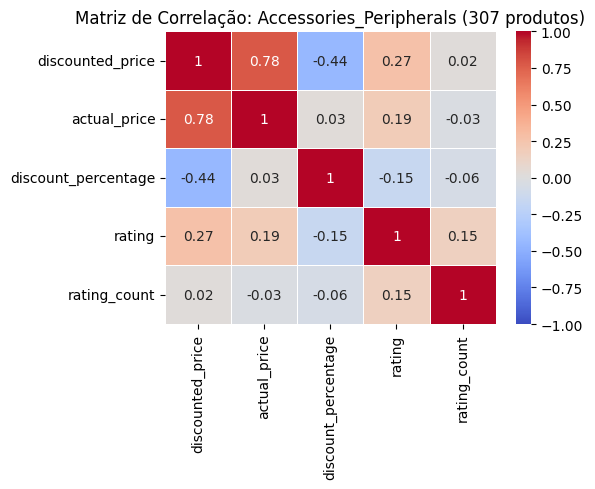

Categoria 'NetworkingDevices' possui apenas 30 registro(s). Correlação não calculada.


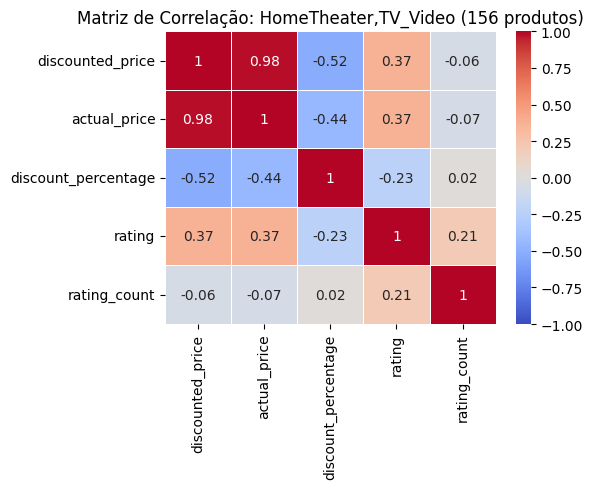

Categoria 'HomeAudio' possui apenas 16 registro(s). Correlação não calculada.


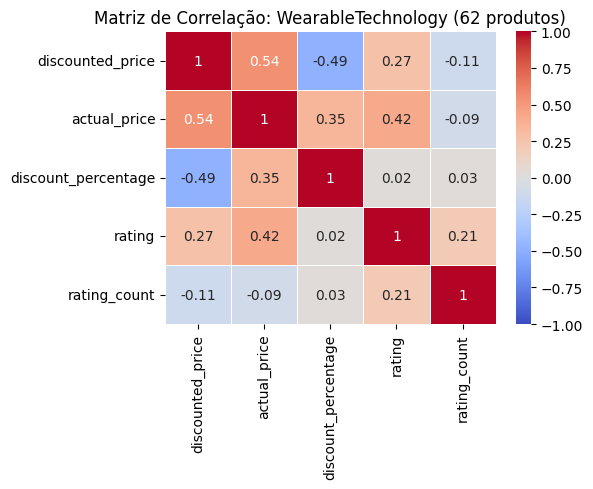

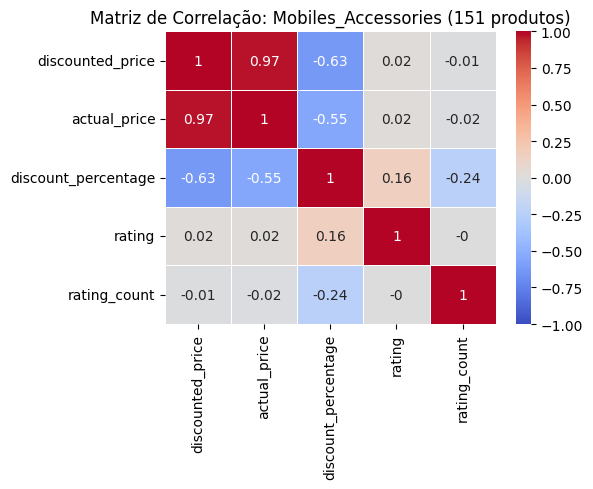

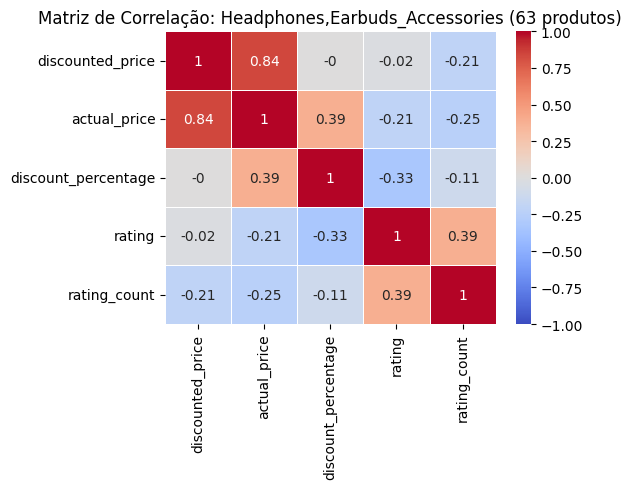

Categoria 'Accessories' possui apenas 11 registro(s). Correlação não calculada.
Categoria 'ExternalDevices_DataStorage' possui apenas 18 registro(s). Correlação não calculada.
Categoria 'Microphones' possui apenas 2 registro(s). Correlação não calculada.
Categoria 'GeneralPurposeBatteries_BatteryChargers' possui apenas 14 registro(s). Correlação não calculada.
Categoria 'OfficePaperProducts' possui apenas 27 registro(s). Correlação não calculada.
Categoria 'CraftMaterials' possui apenas 7 registro(s). Correlação não calculada.
Categoria 'Cameras_Photography' possui apenas 16 registro(s). Correlação não calculada.
Categoria 'OfficeElectronics' possui apenas 4 registro(s). Correlação não calculada.
Categoria 'Printers,Inks_Accessories' possui apenas 11 registro(s). Correlação não calculada.
Categoria 'Monitors' possui apenas 2 registro(s). Correlação não calculada.
Categoria 'Components' possui apenas 5 registro(s). Correlação não calculada.
Categoria 'Electrical' possui apenas 2 registr

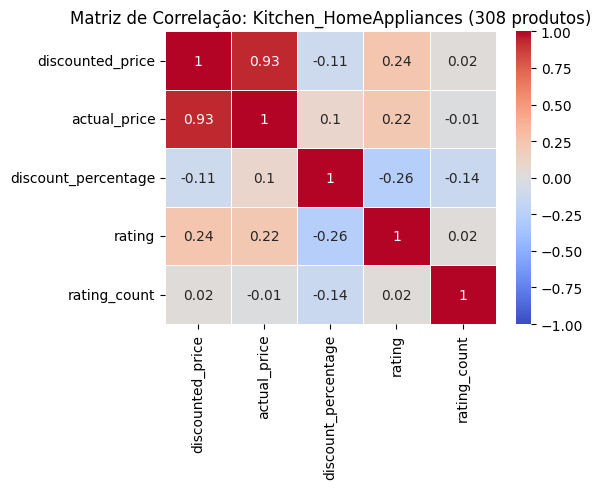

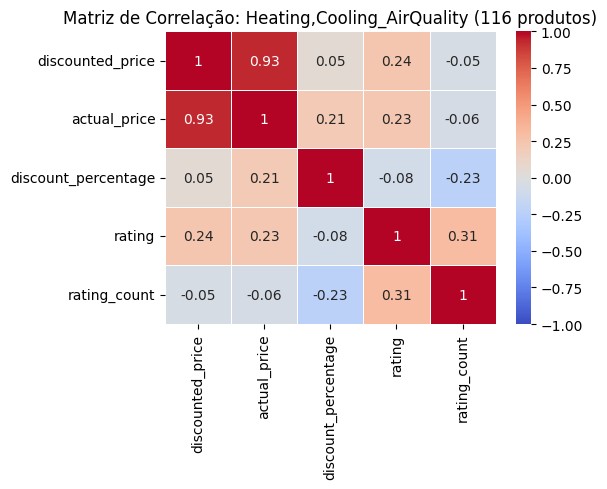

Categoria 'Kitchen_Dining' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'HomeStorage_Organization' possui apenas 16 registro(s). Correlação não calculada.
Categoria 'CarAccessories' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'HomeMedicalSupplies_Equipment' possui apenas 1 registro(s). Correlação não calculada.


In [24]:
# Gerando o gráfico de correlação para cada categoria de produto
for nome_categoria, df_cat in dfs_categorias.items():
    # Verificamos se há registros suficientes para apresentar a matriz exploratória com amostra mínima
    if len(df_cat) >= 50:
        correlation_matrix = df_cat.corr().round(2)

        fig, ax = plt.subplots(figsize=(6, 5))
        sb.heatmap(data=correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=.5, ax=ax)
        ax.set_title(f"Matriz de Correlação: {nome_categoria} ({len(df_cat)} produtos)")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Categoria '{nome_categoria}' possui apenas {len(df_cat)} registro(s). Correlação não calculada.")

In [25]:
# Visualizando os valores únicos da coluna de categorias criada anteriormente
valores_unicos = df['third_category_level'].unique()
print("Valores únicos da coluna:")
print(valores_unicos)

print("\nQuantidade de valores únicos:")
print(df['third_category_level'].nunique())

Valores únicos da coluna:
['Cables&Accessories' 'NetworkAdapters' 'Accessories' 'Televisions'
 'Projectors' 'SatelliteEquipment' 'MediaStreamingDevices'
 'AVReceivers&Amplifiers' 'Speakers' 'SmartWatches' 'MobileAccessories'
 'Smartphones&BasicMobiles' 'Headphones' 'MemoryCards' 'LaptopAccessories'
 'Adapters' 'PenDrives' 'Keyboards,Mice&InputDevices' 'Condenser'
 'DisposableBatteries' 'Paper' 'Scrapbooking' 'ExternalHardDisks'
 'VideoCameras' 'Calculators' 'Repeaters&Extenders'
 'Inks,Toners&Cartridges' 'PCGamingPeripherals' 'PaintingMaterials'
 'HardDiskBags' 'Flashes' nan 'Routers' 'RechargeableBatteries'
 'USBGadgets' 'SecurityCameras' 'TabletAccessories' 'USBHubs'
 'Audio&VideoAccessories' 'ExternalMemoryCardReaders' 'Memory'
 'UninterruptedPowerSupplies' 'Cases' 'Adapters&Multi-Outlets'
 'InternalSolidStateDrives' 'DataCards&Dongles' 'DrawingMaterials'
 'InternalHardDrives' 'Printers' 'Earpads' 'Drawing&PaintingSupplies'
 'ExternalSolidStateDrives' 'SurgeProtectors' 'CordManageme

In [26]:
# Contando os valores nulos na coluna 'third_category_level'
nulos_terceiro_nivel = df['third_category_level'].isnull().sum()
print(f"Quantidade de linhas nulas em 'third_category_level': {nulos_terceiro_nivel}")

Quantidade de linhas nulas em 'third_category_level': 8


In [27]:
# Criando um dicionário para armazenar o DataFrame de cada categoria
dfs_categorias = {}

# Filtrando e criando um DataFrame para cada categoria única
for categoria in df['third_category_level'].unique():
    # Ignora valores nulos (NaN) para evitar erros de tipo
    if pd.isna(categoria):
        continue

    # Substitui caracteres especiais como '&' para criar nomes de chaves mais limpos
    chave_categoria = str(categoria).replace('&', '_')
    dfs_categorias[chave_categoria] = df[df['third_category_level'] == categoria].copy()
    print(f"DataFrame criado para: '{chave_categoria}' com {len(dfs_categorias[chave_categoria])} registros.")

DataFrame criado para: 'Cables_Accessories' com 167 registros.
DataFrame criado para: 'NetworkAdapters' com 16 registros.
DataFrame criado para: 'Accessories' com 94 registros.
DataFrame criado para: 'Televisions' com 66 registros.
DataFrame criado para: 'Projectors' com 3 registros.
DataFrame criado para: 'SatelliteEquipment' com 3 registros.
DataFrame criado para: 'MediaStreamingDevices' com 1 registros.
DataFrame criado para: 'AVReceivers_Amplifiers' com 1 registros.
DataFrame criado para: 'Speakers' com 13 registros.
DataFrame criado para: 'SmartWatches' com 62 registros.
DataFrame criado para: 'MobileAccessories' com 74 registros.
DataFrame criado para: 'Smartphones_BasicMobiles' com 77 registros.
DataFrame criado para: 'Headphones' com 60 registros.
DataFrame criado para: 'MemoryCards' com 11 registros.
DataFrame criado para: 'LaptopAccessories' com 33 registros.
DataFrame criado para: 'Adapters' com 3 registros.
DataFrame criado para: 'PenDrives' com 10 registros.
DataFrame cria

In [28]:
# Colunas desejadas
colunas_filtradas = ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']

# Filtrando as colunas em cada DataFrame do dicionário
for chave in dfs_categorias.keys():
    dfs_categorias[chave] = dfs_categorias[chave][colunas_filtradas]

# Exibindo o cabeçalho de um dos DataFrames para confirmar a alteração
print("Colunas no DataFrame de 'Accessories' após a filtragem:")
display(dfs_categorias['Accessories'].head())

Colunas no DataFrame de 'Accessories' após a filtragem:


,discounted_price,actual_price,discount_percentage,rating,rating_count
12,219.0,700.0,69,4.4,426973.0
21,279.0,499.0,44,3.7,10962.0
25,199.0,699.0,72,4.2,12153.0
47,309.0,475.0,35,4.4,426973.0
48,399.0,999.0,60,3.6,493.0


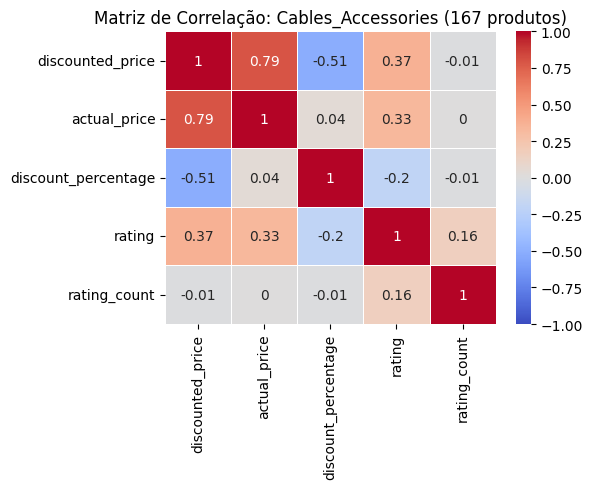

Categoria 'NetworkAdapters' possui apenas 16 registro(s). Correlação não calculada.


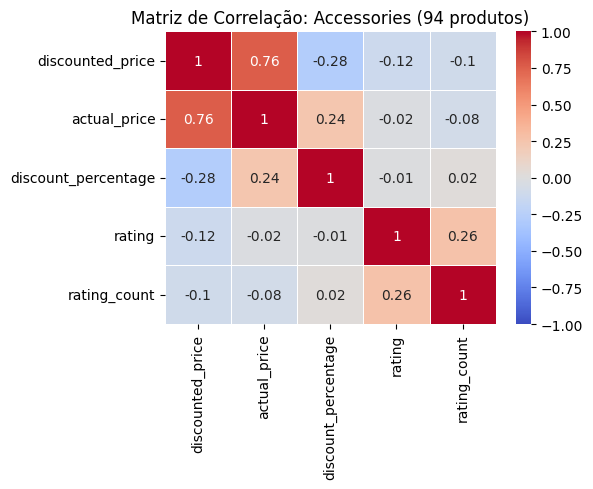

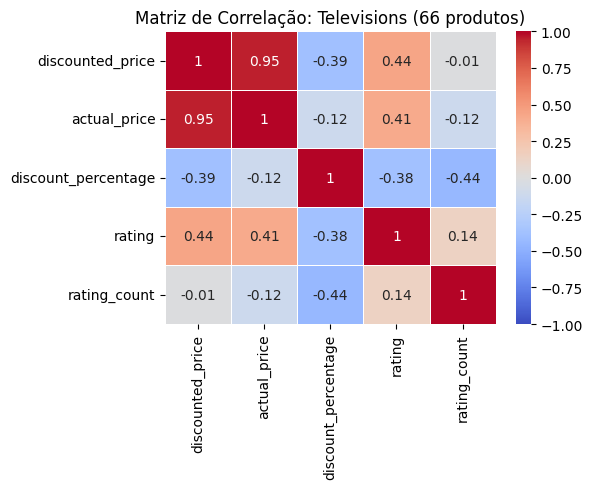

Categoria 'Projectors' possui apenas 3 registro(s). Correlação não calculada.
Categoria 'SatelliteEquipment' possui apenas 3 registro(s). Correlação não calculada.
Categoria 'MediaStreamingDevices' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'AVReceivers_Amplifiers' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'Speakers' possui apenas 13 registro(s). Correlação não calculada.


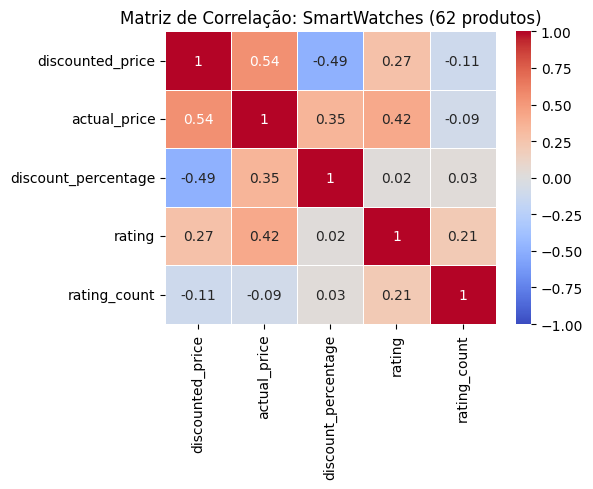

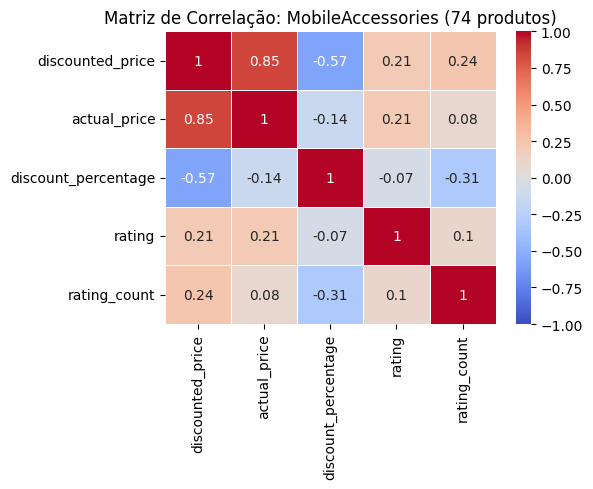

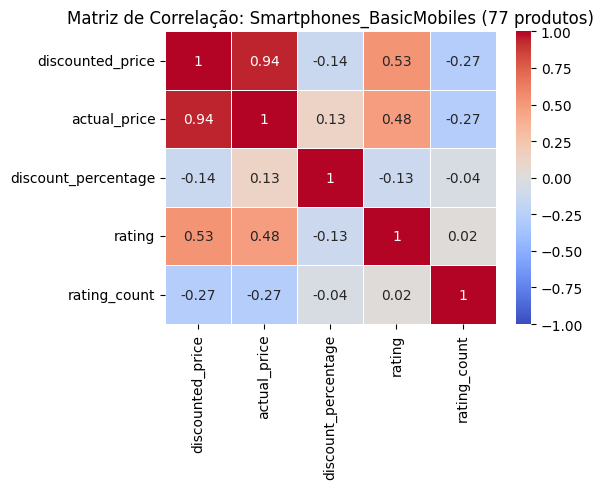

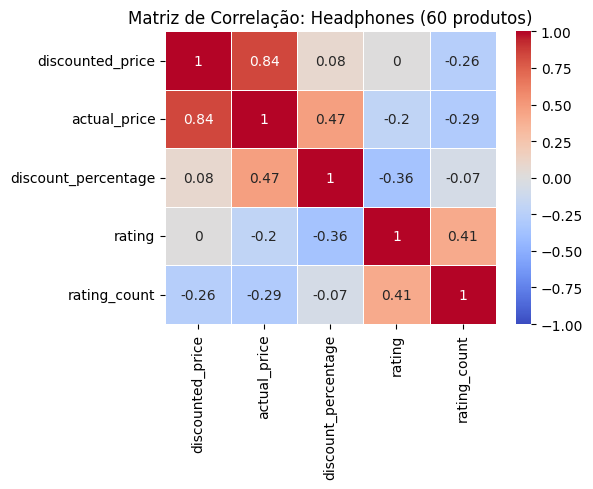

Categoria 'MemoryCards' possui apenas 11 registro(s). Correlação não calculada.
Categoria 'LaptopAccessories' possui apenas 33 registro(s). Correlação não calculada.
Categoria 'Adapters' possui apenas 3 registro(s). Correlação não calculada.
Categoria 'PenDrives' possui apenas 10 registro(s). Correlação não calculada.


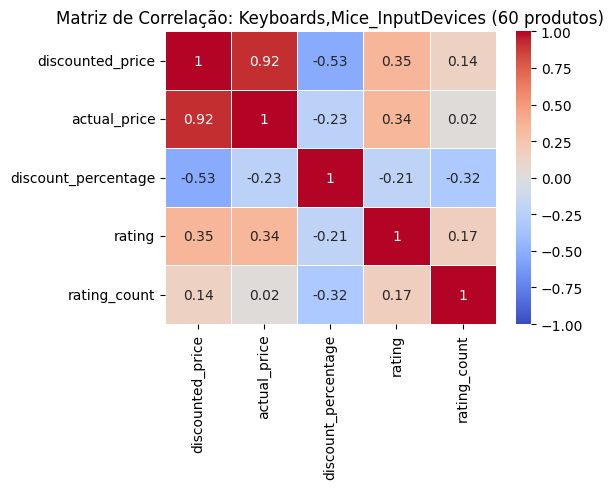

Categoria 'Condenser' possui apenas 2 registro(s). Correlação não calculada.
Categoria 'DisposableBatteries' possui apenas 7 registro(s). Correlação não calculada.
Categoria 'Paper' possui apenas 27 registro(s). Correlação não calculada.
Categoria 'Scrapbooking' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'ExternalHardDisks' possui apenas 6 registro(s). Correlação não calculada.
Categoria 'VideoCameras' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'Calculators' possui apenas 4 registro(s). Correlação não calculada.
Categoria 'Repeaters_Extenders' possui apenas 3 registro(s). Correlação não calculada.
Categoria 'Inks,Toners_Cartridges' possui apenas 6 registro(s). Correlação não calculada.
Categoria 'PCGamingPeripherals' possui apenas 15 registro(s). Correlação não calculada.
Categoria 'PaintingMaterials' possui apenas 4 registro(s). Correlação não calculada.
Categoria 'HardDiskBags' possui apenas 3 registro(s). Correlação não calculada.
Categori

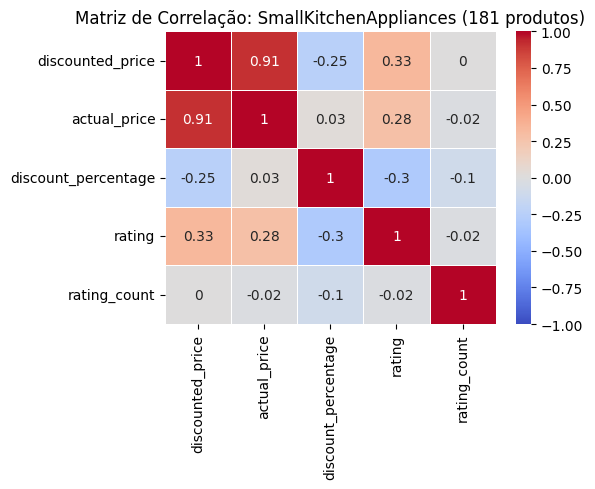

Categoria 'RoomHeaters' possui apenas 46 registro(s). Correlação não calculada.


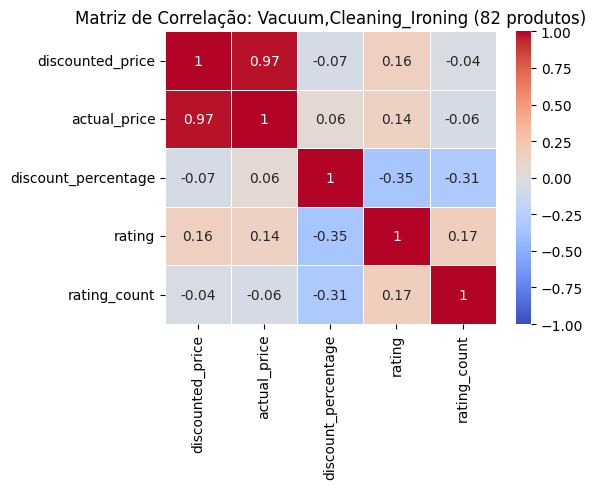

Categoria 'KitchenTools' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'WaterHeaters_Geysers' possui apenas 44 registro(s). Correlação não calculada.
Categoria 'LaundryOrganization' possui apenas 16 registro(s). Correlação não calculada.
Categoria 'Fans' possui apenas 17 registro(s). Correlação não calculada.
Categoria 'Coffee,Tea_Espresso' possui apenas 15 registro(s). Correlação não calculada.
Categoria 'WaterPurifiers_Accessories' possui apenas 26 registro(s). Correlação não calculada.
Categoria 'InteriorAccessories' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'AirPurifiers' possui apenas 4 registro(s). Correlação não calculada.
Categoria 'SewingMachines_Accessories' possui apenas 4 registro(s). Correlação não calculada.
Categoria 'HealthMonitors' possui apenas 1 registro(s). Correlação não calculada.
Categoria 'Humidifiers' possui apenas 3 registro(s). Correlação não calculada.
Categoria 'AirConditioners' possui apenas 1 registro(s). Correlaç

In [29]:
# Gerando o gráfico de correlação para cada categoria de produto
for nome_categoria, df_cat in dfs_categorias.items():
    # Verificamos se há registros suficientes para apresentar a matriz exploratória com amostra mínima
    if len(df_cat) >= 50:
        correlation_matrix = df_cat.corr().round(2)

        fig, ax = plt.subplots(figsize=(6, 5))
        sb.heatmap(data=correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=.5, ax=ax)
        ax.set_title(f"Matriz de Correlação: {nome_categoria} ({len(df_cat)} produtos)")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Categoria '{nome_categoria}' possui apenas {len(df_cat)} registro(s). Correlação não calculada.")

In [30]:

import pandas as pd
import numpy as np

# Configurações
MIN_REGISTROS = 50

niveis = [
    'first_category_level',
    'second_category_level',
    'third_category_level'
]

variaveis = [
    'actual_price',
    'discounted_price',
    'discount_percentage',
    'rating_count'
]

resultados = []

# Análise por nível e categoria
for nivel in niveis:
    for categoria, grupo in df.groupby(nivel):

        if pd.isna(categoria):
            continue

        for variavel in variaveis:

            # Pares válidos para cada correlação
            dados = grupo[['rating', variavel]].dropna()
            n = len(dados)

            if n < MIN_REGISTROS:
                continue

            # Evita correlação indefinida
            if dados['rating'].nunique() < 2:
                continue
            if dados[variavel].nunique() < 2:
                continue

            r = dados['rating'].corr(
                dados[variavel],
                method='pearson'
            )

            resultados.append({
                'Nivel': nivel,
                'Categoria': categoria,
                'Variavel': variavel,
                'Registros': n,
                'Produtos_unicos': grupo.loc[
                    dados.index, 'product_id'
                ].nunique(),
                'Correlacao': r,
                'Forca_absoluta': abs(r)
            })

# DataFrame consolidado
df_correlacoes = pd.DataFrame(resultados)

# Identifica a variável mais forte por categoria
idx = df_correlacoes.groupby(
    ['Nivel', 'Categoria']
)['Forca_absoluta'].idxmax()

df_mais_fortes = (
    df_correlacoes.loc[idx]
    .sort_values('Forca_absoluta', ascending=False)
    .reset_index(drop=True)
)

display(df_mais_fortes.round(3))


,Nivel,Categoria,Variavel,Registros,Produtos_unicos,Correlacao,Forca_absoluta
0,third_category_level,Smartphones&BasicMobiles,discounted_price,77,77,0.529,0.529
1,third_category_level,Televisions,discounted_price,66,66,0.436,0.436
2,third_category_level,SmartWatches,actual_price,62,62,0.417,0.417
3,second_category_level,WearableTechnology,actual_price,62,62,0.417,0.417
4,third_category_level,Headphones,rating_count,60,60,0.413,0.413
5,second_category_level,"Headphones,Earbuds&Accessories",rating_count,63,63,0.387,0.387
6,second_category_level,"HomeTheater,TV&Video",discounted_price,156,156,0.371,0.371
7,third_category_level,Cables&Accessories,discounted_price,167,167,0.369,0.369
8,third_category_level,"Keyboards,Mice&InputDevices",discounted_price,60,60,0.354,0.354
9,third_category_level,"Vacuum,Cleaning&Ironing",discount_percentage,81,81,-0.353,0.353


### 5. Variável com maior associação ao `rating` por categoria

Para cada categoria e nível, são calculadas correlações de Pearson entre `rating` e `actual_price`, `discounted_price`, `discount_percentage` e `rating_count`, exigindo **ao menos 50 pares válidos** por variável. A variável de maior associação é selecionada pelo **valor absoluto** de `r`, preservando seu sinal para interpretação.

Como cada `product_id` aparece uma única vez, a contagem de produtos únicos coincide com o número de pares válidos. O ranking é exploratório: a seleção de máximos entre muitos grupos pode destacar associações instáveis.

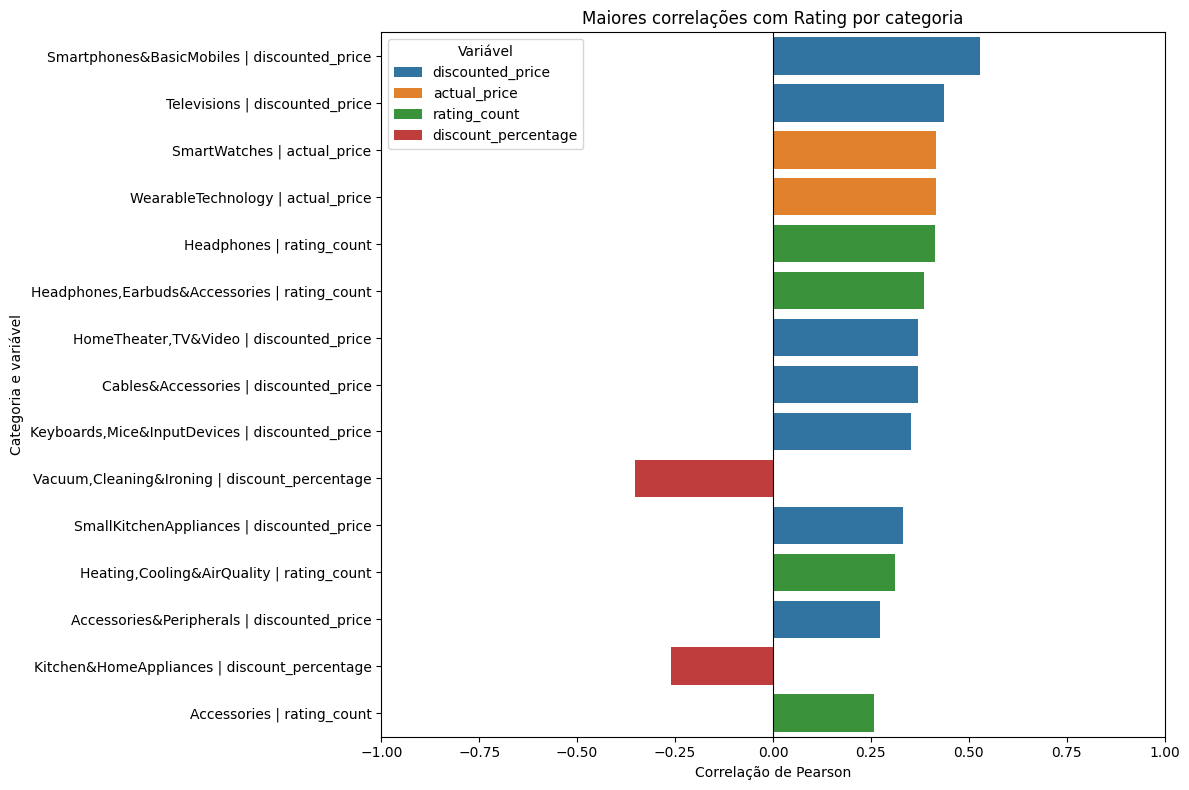

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

top15 = df_mais_fortes.head(15).copy()

top15['Descricao'] = (
    top15['Categoria'] + ' | ' + top15['Variavel']
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top15,
    x='Correlacao',
    y='Descricao',
    hue='Variavel',
    dodge=False
)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlim(-1, 1)

plt.title('Maiores correlações com Rating por categoria')
plt.xlabel('Correlação de Pearson')
plt.ylabel('Categoria e variável')
plt.legend(title='Variável')
plt.tight_layout()
plt.show()


### 6. Interpretação e conclusão dos resultados

Após a deduplicação por `product_id`, a base passou de **1,465 para 1,351 produtos únicos** (remoção de 114 registros excedentes). O registro representativo de cada produto foi selecionado pelo maior `rating_count` numérico.

Na base completa deduplicada, a correlação entre `rating` e `discounted_price` foi **r = 0.126**, indicando associação linear positiva muito fraca. A segmentação revelou associações maiores em determinados grupos: `Smartphones&BasicMobiles` apresentou **r = 0.529** entre `rating` e `discounted_price` (**77 produtos**), e `Televisions` apresentou **r = 0.436** (**66 produtos**). Também se destacaram relações com `actual_price` e `rating_count` em outras categorias.

**Conclusão:** a força e a direção das associações variam conforme o segmento, o que justifica a investigação por categorias em complemento à visão agregada. Os achados são exploratórios e não demonstram causalidade ou significância estatística; análises de sensibilidade a outliers, intervalos de confiança e testes adicionais são recomendados.